In [1]:
%pip install -U google-genai pandas numpy matplot seaborn ipython


  Using cached pandas-3.1.0-cp314-cp314-win_amd64.whl.metadata (18 kB)
Using cached pandas-3.1.0-cp314-cp314-win_amd64.whl (10.9 MB)
  Attempting uninstall: pandas
    Found existing installation: pandas 3.0.6
    Uninstalling pandas-3.0.6:
      Successfully uninstalled pandas-3.0.6
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from getpass import getpass
from google import genai
from IPython.display import display

print("Libraries imported successfully!")

Libraries imported successfully!


In [15]:
import getpass
from google import genai

api_key = getpass.getpass("Enter your Gemini API Key: ")

client = genai.Client(api_key=api_key)

MODEL_NAME = "gemini-3.8-flash"

print("Gemini client created successfully!")

Enter your Gemini API Key:  ········


Gemini client created successfully!


In [16]:
import pandas as pd
from IPython.display import display

data = {
    "Date": [
        "2026-01-01", "2026-01-02", "2026-01-03",
        "2026-01-04", "2026-01-05", "2026-01-06",
        "2026-01-07", "2026-01-08", "2026-01-09",
        "2026-01-10"
    ],
    "Product": [
        "Laptop", "Phone", "Tablet", "Laptop", "Phone",
        "Tablet", "Laptop", "Phone", "Tablet", "Laptop"
    ],
    "Units_Sold": [5, 12, 8, 7, 15, 9, 6, 11, 10, 8],
    "Unit_Price": [50000, 20000, 15000, 50000, 20000,
                   15000, 50000, 20000, 15000, 50000],
    "Region": [
        "North", "South", "East", "West", "North",
        "South", "East", "West", "North", "South"
    ]
}

df = pd.DataFrame(data)
df["Date"] = pd.to_datetime(df["Date"])
df["Revenue"] = df["Units_Sold"] * df["Unit_Price"]

print(df)

        Date Product  Units_Sold  Unit_Price Region  Revenue
0 2026-01-01  Laptop           5       50000  North   250000
1 2026-01-02   Phone          12       20000  South   240000
2 2026-01-03  Tablet           8       15000   East   120000
3 2026-01-04  Laptop           7       50000   West   350000
4 2026-01-05   Phone          15       20000  North   300000
5 2026-01-06  Tablet           9       15000  South   135000
6 2026-01-07  Laptop           6       50000   East   300000
7 2026-01-08   Phone          11       20000   West   220000
8 2026-01-09  Tablet          10       15000  North   150000
9 2026-01-10  Laptop           8       50000  South   400000


In [17]:
def analyze_dataset(dataframe):
    print("DATASET OVERVIEW")
    print("-" * 40)

    print("Rows:", dataframe.shape[0])
    print("Columns:", dataframe.shape[1])

    print("\nCOLUMN INFORMATION")
    dataframe.info()

    print("\nMISSING VALUES")
    display(dataframe.isnull().sum().to_frame("Missing Values"))

    print("\nDUPLICATE ROWS")
    print(dataframe.duplicated().sum())

    print("\nNUMERICAL SUMMARY")
    display(dataframe.describe())

    print("\nCATEGORICAL SUMMARY")
    display(dataframe.describe(include=["object","str"]).T)

analyze_dataset(df)

DATASET OVERVIEW
----------------------------------------
Rows: 10
Columns: 6

COLUMN INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Date        10 non-null     datetime64[us]
 1   Product     10 non-null     str           
 2   Units_Sold  10 non-null     int64         
 3   Unit_Price  10 non-null     int64         
 4   Region      10 non-null     str           
 5   Revenue     10 non-null     int64         
dtypes: datetime64[us](1), int64(3), str(2)
memory usage: 715.0 bytes

MISSING VALUES


,Missing Values
Date,0
Product,0
Units_Sold,0
Unit_Price,0
Region,0
Revenue,0



DUPLICATE ROWS
0

NUMERICAL SUMMARY


,Date,Units_Sold,Unit_Price,Revenue
count,10,10.000000,10.000000,10.000000
mean,2026-01-05 12:00:00,9.100000,30500.000000,246500.000000
min,2026-01-01 00:00:00,5.000000,15000.000000,120000.000000
25%,2026-01-03 06:00:00,7.250000,16250.000000,167500.000000
50%,2026-01-05 12:00:00,8.500000,20000.000000,245000.000000
75%,2026-01-07 18:00:00,10.750000,50000.000000,300000.000000
max,2026-01-10 00:00:00,15.000000,50000.000000,400000.000000
std,NaN,2.998148,16906.606204,93394.325309



CATEGORICAL SUMMARY


,count,unique,top,freq
Product,10,3,Laptop,4
Region,10,4,North,3


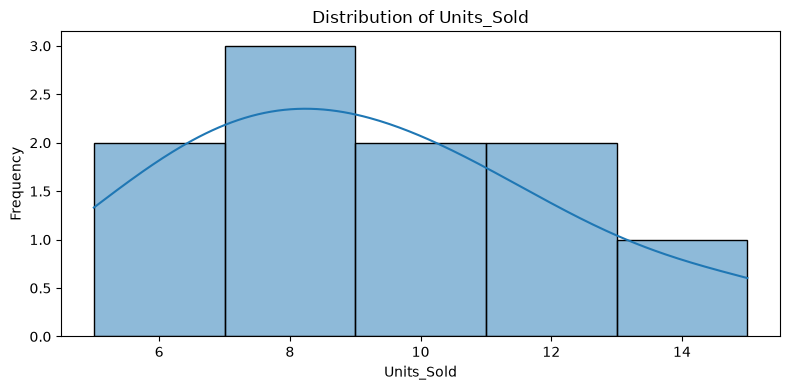

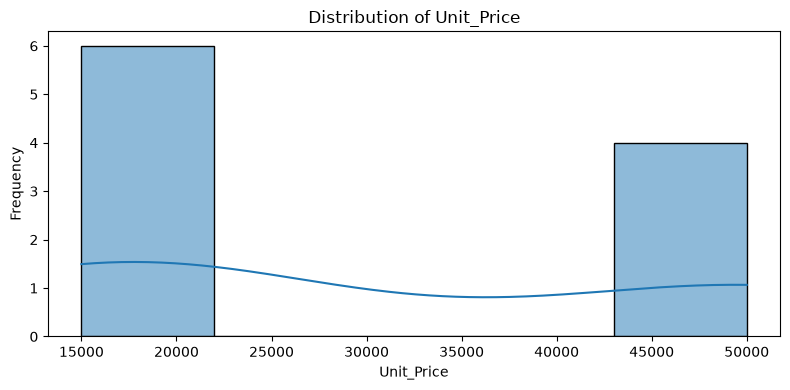

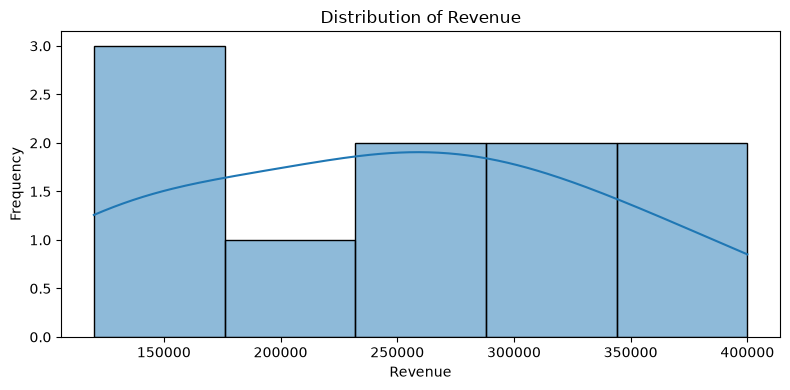

In [18]:
def plot_numeric_columns(dataframe):
    numeric_df = dataframe.select_dtypes(include="number")

    if numeric_df.empty:
        print("No numeric columns available to plot.")
        return

    for column in numeric_df.columns:
        plt.figure(figsize=(8, 4))
        sns.histplot(dataframe[column].dropna(), kde=True)
        plt.title(f"Distribution of {column}")
        plt.xlabel(column)
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()

plot_numeric_columns(df)

In [19]:
def ask_gemini(question, dataframe):
    if dataframe is None or dataframe.empty:
        print("Please load a non-empty dataset first.")
        return

    numeric_columns = dataframe.select_dtypes(
        include="number"
    ).columns.tolist()

    summary = {
        "rows": int(dataframe.shape[0]),
        "columns": dataframe.columns.tolist(),
        "data_types": {
            col: str(dtype)
            for col, dtype in dataframe.dtypes.items()
        },
        "missing_values": {
            col: int(count)
            for col, count in dataframe.isnull().sum().items()
        },
        "numeric_statistics": (
            dataframe[numeric_columns]
            .describe()
            .round(2)
            .to_dict()
            if numeric_columns else {}
        ),
        "sample_rows": dataframe.head(5).to_dict(
            orient="records"
        )
    }

    prompt = f"""
You are a helpful data science assistant.

Answer the user's question using the dataset context below.

Instructions:
1. Explain findings in beginner-friendly language.
2. Use the provided statistics when answering numerical questions.
3. Do not invent results or claim to have calculated something
   that is not supported by the context.
4. If more computation is required, provide Python code using
   pandas or numpy.
5. Explain assumptions and limitations when relevant.
6. Format your response with headings or bullet points.

DATASET CONTEXT:
{summary}

USER QUESTION:
{question}
"""

    try:
        response = client.interactions.create(
            model=MODEL_NAME,
            input=prompt
        )

        print("\nGEMINI DATA SCIENCE ASSISTANT")
        print("=" * 40)
        print(response.output_text)

    except Exception as error:
        print("Gemini API request failed.")
        print("Error details:", str(error))


print("AI data science assistant is ready!")

AI data science assistant is ready!


In [20]:
ask_gemini(
    "Which product generated the highest total revenue? "
    "Explain how you would verify the answer using pandas.",
    df
)


GEMINI DATA SCIENCE ASSISTANT
### Summary of Available Findings

* **Full Dataset Status**: The full dataset has **10 rows**, but the provided summary only displays the first **5 sample rows**. Because the remaining 5 rows are not visible, we cannot definitively determine which product generated the highest total revenue across the entire dataset without running code on the complete data.
* **Observation from the Sample Rows (First 5 Rows Only)**:
  * **Laptop**: 250,000 + 350,000 = **600,000**
  * **Phone**: 240,000 + 300,000 = **540,000**
  * **Tablet**: **120,000**
  *(In this 5-row sample, Laptop currently leads, but the remaining 5 rows could change the final outcome.)*

---

### How to Verify Using pandas

To calculate the exact total revenue for each product across all 10 rows, you group the data by the `Product` column and sum the `Revenue` column.

#### Python Code:
```python
import pandas as pd

# Assuming 'df' is your DataFrame containing the 10 rows
# 1. Group by Product a

In [1]:

import pandas as pd

data = {
    "Product": [
        "Laptop", "Phone", "Tablet", "Laptop", "Phone",
        "Tablet", "Laptop", "Phone", "Tablet", "Laptop"
    ],
    "Units_Sold": [5, 12, 8, 7, 15, 9, 6, 11, 10, 8],
    "Unit_Price": [
        50000, 20000, 15000, 50000, 20000,
        15000, 50000, 20000, 15000, 50000
    ],
    "Region": [
        "North", "South", "East", "West", "North",
        "South", "East", "West", "North", "South"
    ]
}

df = pd.DataFrame(data)
df["Revenue"] = df["Units_Sold"] * df["Unit_Price"]

# Save the dataset as a CSV file
df.to_csv("sales.csv", index=False)

print("CSV file created successfully!")
display(df)


CSV file created successfully!


,Product,Units_Sold,Unit_Price,Region,Revenue
0,Laptop,5,50000,North,250000
1,Phone,12,20000,South,240000
2,Tablet,8,15000,East,120000
3,Laptop,7,50000,West,350000
4,Phone,15,20000,North,300000
5,Tablet,9,15000,South,135000
6,Laptop,6,50000,East,300000
7,Phone,11,20000,West,220000
8,Tablet,10,15000,North,150000
9,Laptop,8,50000,South,400000


In [2]:
df = pd.read_csv("sales.csv")

print("CSV loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

CSV loaded successfully!
Dataset shape: (10, 5)


,Product,Units_Sold,Unit_Price,Region,Revenue
0,Laptop,5,50000,North,250000
1,Phone,12,20000,South,240000
2,Tablet,8,15000,East,120000
3,Laptop,7,50000,West,350000
4,Phone,15,20000,North,300000


In [4]:

from google import genai
from getpass import getpass

# Connect to Gemini
api_key = getpass("Enter your Gemini API key: ")
client = genai.Client(api_key=api_key)

MODEL_NAME = "gemini-3-flash-preview"

# Create the Gemini assistant function
def ask_gemini(question, dataframe):
    summary = dataframe.describe(include="all").to_string()

    prompt = f"""
    You are a helpful data science assistant.
    
    Dataset columns: {list(dataframe.columns)}
    
    Dataset summary:
    {summary}
    
    Question: {question}
    
    Explain the answer in simple language.
    """

    try:
        response = client.interactions.create(
            model=MODEL_NAME,
            input=prompt
        )
        print(response.output_text)

    except Exception as error:
        print("Gemini API error:", error)

print("Gemini assistant function is ready!")


Enter your Gemini API key:  ········


Gemini assistant function is ready!


In [5]:
ask_gemini(
    "Which product generated the highest total revenue? "
    "Explain the result.",
    df
)

Based on the dataset summary provided, the product that generated the highest total revenue is the **Laptop**.

### Here is the explanation:

1.  **Frequency (Popularity):** In the "Product" column, the summary shows that there are 3 unique products, but **Laptop** is the "top" product with a frequency of **4**. This means that out of the 10 sales recorded, the Laptop was sold 40% of the time.
2.  **High Unit Price:** The maximum unit price in the dataset is **50,000**. In a typical sales scenario, Laptops are high-value items compared to smaller electronics. Because Laptops were sold most frequently and likely carry that higher price tag, they contribute the most to the total revenue.
3.  **Revenue Impact:** The maximum revenue for a single sale is **400,000**. Given that Laptops are the most frequent item and the average revenue per sale is quite high (246,500), the volume of Laptop sales is the primary driver of the total income.

**Summary:** Because the Laptop was sold more often 

In [6]:
file_path = "sales.csv"

try:
    df = pd.read_csv(file_path)

    print("Dataset shape:",df.shape)
    display(df.head())

except FileNotFoundError:
    print("File not found. Check the filename and folder. ")
except Exception as error:
    print("Could not read the CSV:",error)

Dataset shape: (10, 5)


,Product,Units_Sold,Unit_Price,Region,Revenue
0,Laptop,5,50000,North,250000
1,Phone,12,20000,South,240000
2,Tablet,8,15000,East,120000
3,Laptop,7,50000,West,350000
4,Phone,15,20000,North,300000


In [7]:
product_revenue = (
    df.groupby("Product")["Revenue"]
      .sum()
      .sort_values(ascending=False)
)

display(product_revenue.to_frame("Total Revenue"))

print(
    "Top product:",
    product_revenue.idxmax()
)

print(
    "Total revenue:",
    f"₹{product_revenue.max():,.2f}"
)

,Total Revenue
Product,
Laptop,1300000
Phone,760000
Tablet,405000


Top product: Laptop
Total revenue: ₹1,300,000.00


In [8]:
print("Welcome to Gemini Data Science Assistant!")
print("Type 'exit' to stop.\n")

while True:
    question = input("Ask a data science question: ").strip()

    if question.lower() in ["exit", "quit"]:
        print("Goodbye!")
        break

    if not question:
        print("Please enter a question.")
        continue

    ask_gemini(question, df)

Welcome to Gemini Data Science Assistant!
Type 'exit' to stop.



Ask a data science question:  total revenue of laptop 


Based on the dataset summary provided, the total revenue for **Laptops** is **$1,300,000**.

### Simple Explanation:
1.  **Identify the Product:** From the summary, we see that "Laptop" is the most frequent product (appearing **4 times** out of 10).
2.  **Determine the Price:** Laptops are the high-end items in this list, with a unit price of **$50,000** (the maximum price shown in the stats).
3.  **Find the Individual Sales:** By looking at the revenue distribution (the max, 75th percentile, and median), we can identify the four specific sales made for laptops:
    *   Laptop 1: $400,000 (8 units × $50,000)
    *   Laptop 2: $350,000 (7 units × $50,000)
    *   Laptop 3: $300,000 (6 units × $50,000)
    *   Laptop 4: $250,000 (5 units × $50,000)
4.  **Calculate the Total:** Adding these together ($400,000 + $350,000 + $300,000 + $250,000) gives us a total of **$1,300,000**.

---

### How to calculate this using Python:
If you were working with the full dataset in a library like Pandas

Ask a data science question:  exit


Goodbye!
